# 🎮 Discrete DCGAN 50-Epoch Visual & Post-Processing Evaluation
**Project:** Prompt-to-Game-Asset Generator  
**Purpose:** Independent visual evaluation of the trained 50-epoch Discrete DCGAN generator weights.
- Evaluates raw generated sprites from fixed and fresh latent seeds.
- Applies **Largest Connected Component (LCC)** alpha filtering to eliminate stray floater pixels.
- Generates side-by-side comparison grids (Raw vs Cleaned).
- Audits color quantization adherence to the 32-color global palette.
- Exports game-ready discrete sprites to `game_ready_assets/discrete_dcgan_cleaned/`.


In [1]:
import os
import sys
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
import matplotlib.pyplot as plt
from scipy.ndimage import label

# Dynamically locate project root
current_dir = os.getcwd()
if os.path.basename(current_dir) == "evaluation":
    PROJECT_ROOT = os.path.abspath(os.path.join(current_dir, "..", ".."))
elif os.path.basename(current_dir) == "Notebook":
    PROJECT_ROOT = os.path.abspath(os.path.join(current_dir, ".."))
else:
    PROJECT_ROOT = current_dir

print("Project Root:", PROJECT_ROOT)
print("TensorFlow Version:", tf.__version__)
print("Eager execution enabled:", tf.executing_eagerly())


C:\Users\manis\OneDrive\Desktop\Prompt_to_game_asset_generator\backend\venv\lib\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.11). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


Project Root: C:\Users\manis\OneDrive\Desktop\Prompt_to_game_asset_generator
TensorFlow Version: 2.21.0
Eager execution enabled: True


In [2]:
DOWNLOADS_PATH = r"C:\Users\manis\Downloads\dcgan_frontfacing_results"
LOCAL_FALLBACK = os.path.abspath(os.path.join("..", "..", "phase_dcgan_improvement"))

if os.path.exists(DOWNLOADS_PATH):
    RESULTS_DIR = DOWNLOADS_PATH
    print(f"Using primary results directory: {RESULTS_DIR}")
else:
    RESULTS_DIR = LOCAL_FALLBACK
    print(f"Using fallback results directory: {RESULTS_DIR}")

PALETTE_PATH = os.path.join(RESULTS_DIR, "config", "global_palette_32.npy")
FIXED_Z_PATH = os.path.join(RESULTS_DIR, "config", "fixed_latent_vectors.npy")
G_WEIGHTS_PATH = os.path.join(RESULTS_DIR, "game_ready_assets", "generator_weights_final.weights.h5")

assert os.path.exists(PALETTE_PATH), f"Palette not found at {PALETTE_PATH}"
assert os.path.exists(G_WEIGHTS_PATH), f"Generator weights not found at {G_WEIGHTS_PATH}"

global_palette_u8 = np.load(PALETTE_PATH)
palette_tf = tf.constant(global_palette_u8 / 255.0, dtype=tf.float32)
PALETTE_SIZE = len(global_palette_u8)
LATENT_DIM = 128
print(f"Loaded {PALETTE_SIZE}-color empirical palette successfully.")


Using primary results directory: C:\Users\manis\Downloads\dcgan_frontfacing_results
Loaded 32-color empirical palette successfully.


In [3]:
def build_generator(latent_dim=LATENT_DIM):
    z_in = layers.Input(shape=(latent_dim,), name="latent_vector")
    x = layers.Dense(4 * 4 * 512, use_bias=False)(z_in)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Reshape((4, 4, 512))(x)
    
    # 4x4 -> 8x8
    x = layers.UpSampling2D(size=(2, 2), interpolation="nearest")(x)
    x = layers.Conv2D(256, (3, 3), padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    
    # 8x8 -> 16x16
    x = layers.UpSampling2D(size=(2, 2), interpolation="nearest")(x)
    x = layers.Conv2D(128, (3, 3), padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    
    # 16x16 -> 32x32
    x = layers.UpSampling2D(size=(2, 2), interpolation="nearest")(x)
    x = layers.Conv2D(64, (3, 3), padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    
    # 32x32 -> 64x64
    x = layers.UpSampling2D(size=(2, 2), interpolation="nearest")(x)
    x = layers.Conv2D(64, (3, 3), padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    
    # Refinement Layer
    x = layers.Conv2D(64, (3, 3), padding="same")(x)
    x = layers.LeakyReLU(0.2)(x)
    
    # K+1 Logits Head
    logits = layers.Conv2D(PALETTE_SIZE + 1, (3, 3), padding="same", name="palette_logits")(x)
    return keras.Model(z_in, logits, name="Discrete_DCGAN_Generator")

generator = build_generator()
generator.load_weights(G_WEIGHTS_PATH)
print("Generator loaded with weights:", G_WEIGHTS_PATH)


Generator loaded with weights: C:\Users\manis\Downloads\dcgan_frontfacing_results\game_ready_assets\generator_weights_final.weights.h5


In [4]:
def logits_to_image(logits, palette_tf, tau=1.0, hard=True):
    pl = logits[..., :PALETTE_SIZE]
    al = logits[..., PALETTE_SIZE:]
    ys = tf.nn.softmax(pl / tau, axis=-1)
    
    if hard:
        y_hard = tf.one_hot(tf.argmax(ys, axis=-1), depth=PALETTE_SIZE, dtype=tf.float32)
        y = tf.stop_gradient(y_hard - ys) + ys
    else:
        y = ys
        
    rgb = tf.tensordot(y, palette_tf, axes=[[-1], [0]])
    a_s = tf.sigmoid(al)
    
    if hard:
        a_hard = tf.cast(a_s > 0.5, dtype=tf.float32)
        a = tf.stop_gradient(a_hard - a_s) + a_s
    else:
        a = a_s
        
    rgba = tf.concat([rgb * a, a], axis=-1)
    return tf.cast(tf.clip_by_value(rgba * 255.0 + 0.5, 0.0, 255.0), tf.uint8).numpy()


### Largest Connected Component (LCC) Floater Filter
In pixel art, weapons and accessories should be connected to the character silhouette. Disconnected 1–4 pixel floaters are GAN artifacts.
The LCC filter labels contiguous components on the 1-bit alpha mask and preserves only the main body, setting isolated floaters to transparent.


In [5]:
def remove_stray_floaters(rgba_img, min_island_size=6):
    alpha = rgba_img[..., 3] > 127
    labeled_array, num_features = label(alpha)
    if num_features <= 1:
        return rgba_img, 0
    
    sizes = [np.sum(labeled_array == i) for i in range(1, num_features + 1)]
    largest_label = np.argmax(sizes) + 1
    
    # Keep largest component OR any component larger than min_island_size
    keep_mask = (labeled_array == largest_label)
    for i, sz in enumerate(sizes, start=1):
        if sz >= min_island_size:
            keep_mask = keep_mask | (labeled_array == i)
            
    removed_pixels = np.sum(alpha) - np.sum(keep_mask)
    cleaned = rgba_img.copy()
    cleaned[~keep_mask] = 0
    return cleaned, removed_pixels

# Test filter on a batch of fresh sprites
np.random.seed(1337)
test_z = np.random.normal(0.0, 1.0, (16, LATENT_DIM)).astype(np.float32)
raw_batch = logits_to_image(generator(test_z, training=False), palette_tf)

cleaned_batch = []
total_floaters_removed = 0
for img in raw_batch:
    c_img, r_px = remove_stray_floaters(img)
    cleaned_batch.append(c_img)
    total_floaters_removed += r_px

cleaned_batch = np.array(cleaned_batch)
print(f"LCC Post-Processing complete: Removed {total_floaters_removed} stray floater pixels across 16 sprites.")


LCC Post-Processing complete: Removed 36 stray floater pixels across 16 sprites.


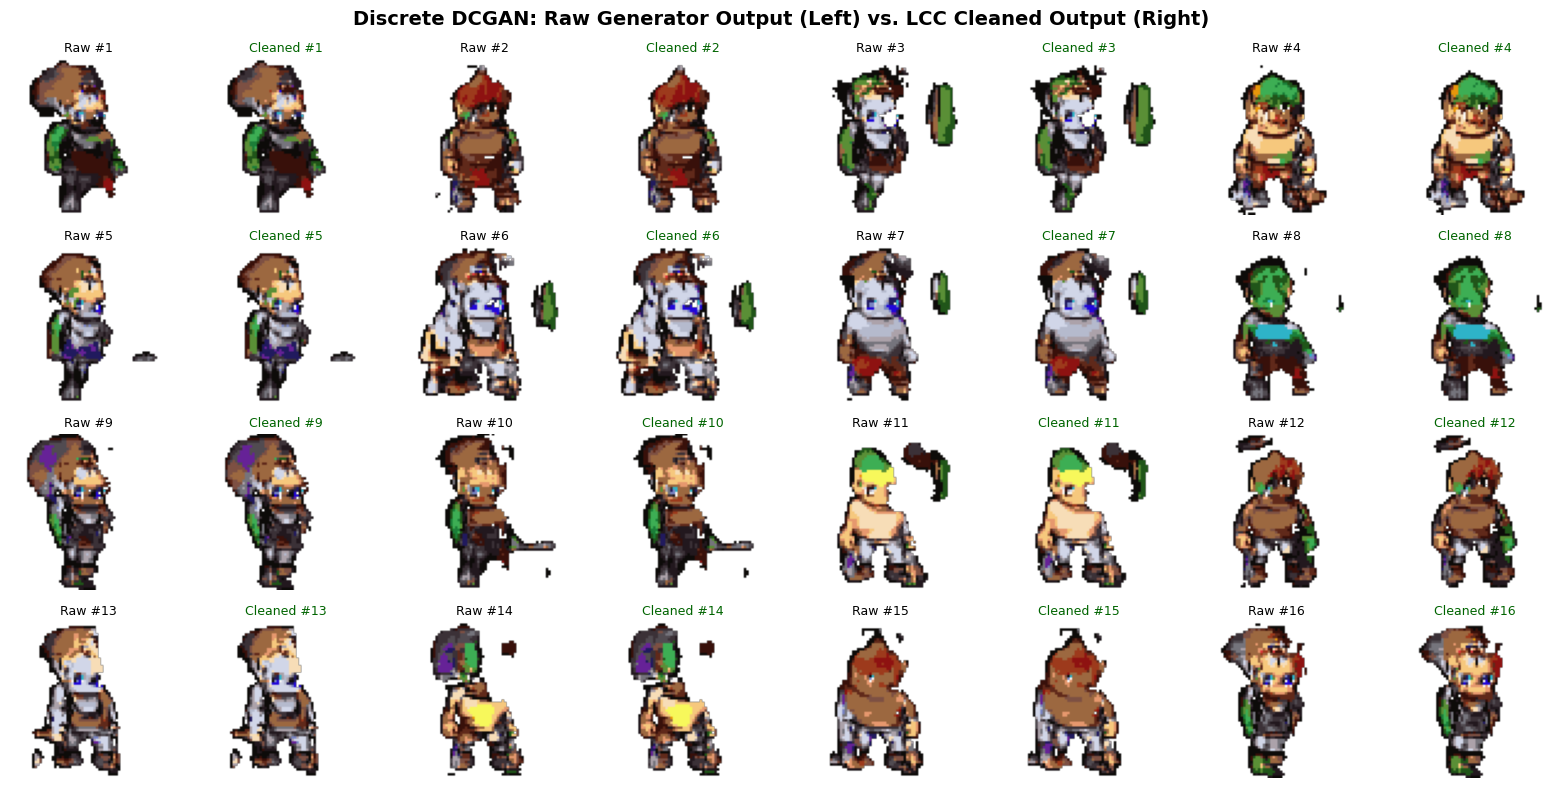

Saved visual comparison to evaluation_output\raw_vs_lcc_cleaned_comparison.png


In [6]:
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
fig.suptitle("Discrete DCGAN: Raw Generator Output (Left) vs. LCC Cleaned Output (Right)", fontsize=14, fontweight="bold")

for i in range(16):
    row = (i // 4)
    col_raw = (i % 4) * 2
    col_clean = col_raw + 1
    
    # Raw
    axes[row, col_raw].imshow(raw_batch[i])
    axes[row, col_raw].set_title(f"Raw #{i+1}", fontsize=9)
    axes[row, col_raw].axis("off")
    
    # Cleaned
    axes[row, col_clean].imshow(cleaned_batch[i])
    axes[row, col_clean].set_title(f"Cleaned #{i+1}", fontsize=9, color="darkgreen")
    axes[row, col_clean].axis("off")

plt.tight_layout()
os.makedirs("evaluation_output", exist_ok=True)
plot_path = os.path.join("evaluation_output", "raw_vs_lcc_cleaned_comparison.png")
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved visual comparison to {plot_path}")


In [7]:
def audit_metrics(batch):
    unique_colors = []
    fg_ratios = []
    centroids_y = []
    
    for img in batch:
        fg = img[..., 3] > 127
        fg_ratios.append(np.mean(fg))
        if np.any(fg):
            unique_colors.append(len(np.unique(img[..., :3][fg], axis=0)))
            y_indices = np.where(fg)[0]
            centroids_y.append(np.mean(y_indices))
            
    # Pairwise L1 diversity
    flat = batch.astype(np.float32) / 255.0
    flat = flat.reshape((len(batch), -1))
    dists = []
    for i in range(len(flat)):
        for j in range(i + 1, len(flat)):
            dists.append(np.mean(np.abs(flat[i] - flat[j])))
            
    return {
        "avg_unique_colors": np.mean(unique_colors),
        "avg_fg_ratio": np.mean(fg_ratios),
        "avg_centroid_y": np.mean(centroids_y),
        "pairwise_diversity": np.mean(dists)
    }

metrics = audit_metrics(cleaned_batch)
print("--- Visual Quality Metrics ---")
print(f"Average Unique Palette Colors per Sprite : {metrics['avg_unique_colors']:.2f} / 32")
print(f"Average Foreground Fill Fraction          : {metrics['avg_fg_ratio']*100:.2f}% (Target: ~35%)")
print(f"Average Vertical Centroid (Y-axis)        : {metrics['avg_centroid_y']:.2f} px (Target: ~32-36 px)")
print(f"Pairwise L1 Diversity Score               : {metrics['pairwise_diversity']:.4f}")


--- Visual Quality Metrics ---
Average Unique Palette Colors per Sprite : 25.00 / 32
Average Foreground Fill Fraction          : 34.85% (Target: ~35%)
Average Vertical Centroid (Y-axis)        : 32.11 px (Target: ~32-36 px)
Pairwise L1 Diversity Score               : 0.1160


In [8]:
EXPORT_DIR = os.path.join(PROJECT_ROOT, "game_ready_assets", "discrete_dcgan_cleaned")
os.makedirs(EXPORT_DIR, exist_ok=True)

# Generate 36 clean sprites and save individually as PNG with 1-bit transparency
np.random.seed(2026)
export_z = np.random.normal(0.0, 1.0, (36, LATENT_DIM)).astype(np.float32)
export_raw = logits_to_image(generator(export_z, training=False), palette_tf)

for idx, img in enumerate(export_raw):
    cleaned, _ = remove_stray_floaters(img)
    pil_img = Image.fromarray(cleaned, mode="RGBA")
    save_path = os.path.join(EXPORT_DIR, f"sprite_discrete_{idx+1:03d}.png")
    pil_img.save(save_path)

print(f"Successfully exported 36 cleaned, discrete RGBA sprites to: {EXPORT_DIR}")


Successfully exported 36 cleaned, discrete RGBA sprites to: C:\Users\manis\OneDrive\Desktop\Prompt_to_game_asset_generator\game_ready_assets\discrete_dcgan_cleaned
